# Single Cell Exploration

This tutorial demonstrates how to handle the single cell reference atlas AnnData for the exploration of hypothalamic populations.

In this notebook, we will:
1. Load and normalize the control single-cell dataset
2. Explore cell-level metadata (dataset, suspension, inferred sex)
3. Visualize hierarchical cluster assignments on UMAPs
4. Identify and validate marker genes for a biologically relevant population
   (KNDy neurons in the arcuate nucleus)


Requirements:
1. `matplotlib` and `scanpy` python packages.
2. HypoMap3D's marker gene table and full single cell object. 

This tutorial assumes basic familiarity with Scanpy and AnnData objects.

In [1]:
# Enable automatic reloading of modules during interactive work (optional)
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt

import pandas as pd
import scanpy as sc

# Conversion factor: millimeters to inches (for publication-style figures)
MM = 1 / 25.4

In [ ]:
# Set the path to each the required objects
FP_SC_ANNDATA = r'REPLACE FILEPATH HERE'
FP_MARKER_TABLE = r'REPLACE FILEPATH HERE'

## Loading the single-cell dataset

We load the **control** single-cell dataset provided as an AnnData (`.h5ad`) file.
This object includes:
- Gene expression raw counts (`adata.X`)
- Cell-level metadata (`adata.obs`)
- Precomputed embeddings such as UMAP (`adata.obsm`)

In [ ]:
# Loading the control dataset via scanpy
adata = sc.read_h5ad(FP_SC_ANNDATA)

# Subset to only control cells
adata = adata[adata.obs['IsControl']].copy()

adata

AnnData object with n_obs × n_vars = 896959 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

## Normalization and transformation

For visualization and downstream exploratory analysis, we normalize the data:
1. Normalize total counts per cell to 10,000 (CP10k)
2. Apply a log1p transformation

This is a standard Scanpy preprocessing workflow for visualization.


In [5]:
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata)

## Accessing cell metadata

Cell-level metadata are stored in `adata.obs`.
These include:
- Quality control metrics e.g. total_counts, and pct_mito
- Sample annotations e.g. Dataset, Sample, and Suspension
- Biological annotations e.g. cluster assignments

Below, we explore the distribution of:
- Dataset
- Suspension
- Inferred sex


In [6]:
# Preview cell metadata
adata.obs.head(4)

,CellID,Dataset,Sample,total_counts,n_genes,pct_mito,Author,Source,Data_source_link,GEO,...,L1_descr,L2_descr,L3_descr,L4_descr,L5_descr,L1_abc_like,L2_abc_like,L3_abc_like,L4_abc_like,L5_abc_like
SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01,SC1-01_SAMN18754353,17459.0,5884,0.131737,Affinati,SRA,NaN,GSE172204,...,Gl1-1 Glut,Gl2-35 VMH Nr5a1.Acvr1c,Gl3-113 VMH Cobll1,Gl4-290 VMH Cobll1.Vgll2,Gl5-390 VMH Cobll1.Vgll2,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-113 VMH Nr5a1 Acvr1c Glut_3c,Gl4-290 VMH Nr5a1 Acvr1c Glut_3c-1,Gl5-390 VMH Nr5a1 Acvr1c Glut_3c-1-1
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01,SC1-01_SAMN18754353,17067.0,5727,0.117185,Affinati,SRA,NaN,GSE172204,...,Gl1-1 Glut,Gl2-33 VMH Fezf1,Gl3-107 VMH Npffr1,Gl4-274 VMH Npffr1.Arhgap36,Gl5-371 VMH Npffr1.Arhgap36.Htr1b,Gl1-1 Glut,Gl2-33 VMH Fezf1 Glut,Gl3-107 VMH Fezf1 Glut_2,Gl4-274 VMH Fezf1 Glut_2-2,Gl5-371 VMH Fezf1 Glut_2-2-1
SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,SC1-01,SC1-01_SAMN18754353,11905.0,4965,0.201596,Affinati,SRA,NaN,GSE172204,...,Gl1-1 Glut,Gl2-35 VMH Nr5a1.Acvr1c,Gl3-111 VMH Rai14,Gl4-286 VMH Rai14.Evc2,Gl5-386 VMH Rai14.Evc2,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-111 VMH Nr5a1 Acvr1c Glut_3a,Gl4-286 VMH Nr5a1 Acvr1c Glut_3a-4,Gl5-386 VMH Nr5a1 Acvr1c Glut_3a-4-1
SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,SC1-01,SC1-01_SAMN18754353,12268.0,5205,0.171177,Affinati,SRA,NaN,GSE172204,...,Gl1-1 Glut,Gl2-35 VMH Nr5a1.Acvr1c,Gl3-113 VMH Cobll1,Gl4-291 VMH Cobll1.Dgkk,Gl5-391 VMH Cobll1.Dgkk,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-113 VMH Nr5a1 Acvr1c Glut_3c,Gl4-291 VMH Nr5a1 Acvr1c Glut_3c-2,Gl5-391 VMH Nr5a1 Acvr1c Glut_3c-2-1


In [8]:
# Count cells per dataset
dataset_counts = adata.obs['Dataset'].value_counts()

# Count cells per suspension
suspension_counts = adata.obs['Suspension'].value_counts()

# Count cells per inferred sex
# Sex is inferred based on Uty and Xist expression using sample-wise thresholds
sex_counts = adata.obs['sex_per_sample_inferred'].value_counts()

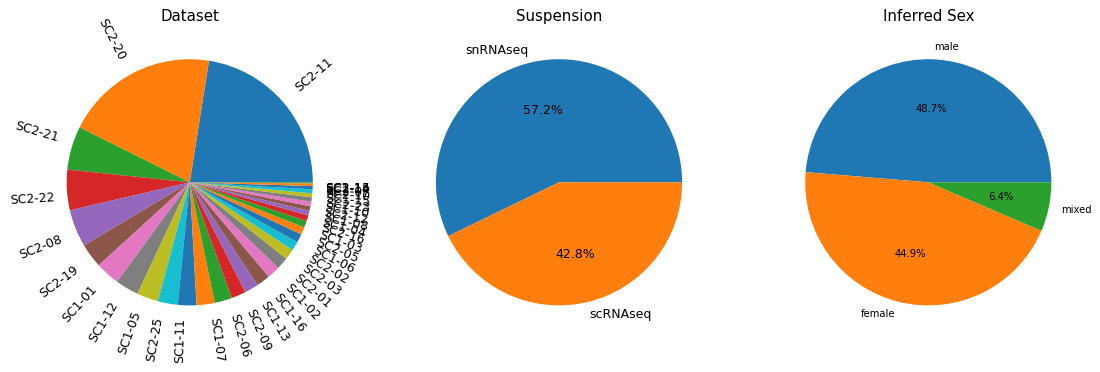

In [9]:
# Visualize metadata distributions using pie charts
fig, axes = plt.subplots(1, 3, figsize=(15,5), dpi=90)

# Dataset distribution ------------------------------------------------------ #
axes[0].pie(
    dataset_counts.values,
    labels=dataset_counts.index,
    textprops=dict(size=10),
    rotatelabels=True
)
axes[0].set_title('Dataset')

# Suspension distribution --------------------------------------------------- #
axes[1].pie(
    suspension_counts.values,
    labels=suspension_counts.index,
    textprops=dict(size=10),
    autopct='%1.1f%%'
)
axes[1].set_title('Suspension')

# Inferred sex distribution ------------------------------------------------- #
axes[2].pie(
    sex_counts.values,
    labels=sex_counts.index,
    textprops=dict(size=8),
    autopct='%1.1f%%'
)
axes[2].set_title('Inferred Sex')

plt.show()
plt.close(fig)

## Cluster assignments

HypoMap3D provides **hierarchical cluster annotations** stored in `adata.obs`.
Each level is available in three complementary representations:

- `L*_ID` → short cluster IDs (e.g. `Gl3-84`)
- `L*_descr` → human-readable taxonomic labels
- `L*_abc_like` → Allen Brain Atlas–compatible labels

Here, we visualize:
1. All Level 1 (L1) cell types
2. The Level 3 (L3) subclusters of a specific L1 population (`Gl1-8`)

In [14]:
adata.obs['L1_descr'].value_counts()

L1_descr
Gb1-2 GABA          328018
Gl1-1 Glut          279075
NN1-1 OPC-Oligo     140839
NN1-4 Astro-Epen    108835
NN1-3 Vascular       22077
NN1-2 Immune         18115
Name: count, dtype: int64

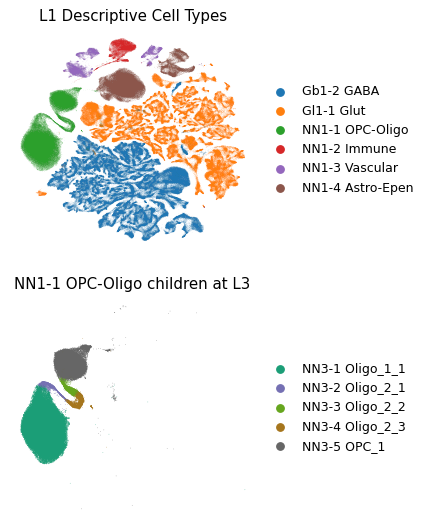

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(90*MM, 180*MM), dpi=90)

# Full L1 UMAP --------------------------------------------------------------- #
sc.pl.umap(
    adata,
    color='L1_descr',
    ax=axes[0],
    show=False,
    frameon=False,
    title='L1 Descriptive Cell Types'
)

# Subset: NN1-1 OPC-Oligo cells and visualize their L3 children ------------------------ #
mask = adata.obs['L1_ID'] == 'NN1-1'
subset = adata[mask].copy()  # Convert view to actual AnnData object

sc.pl.umap(
    subset,
    color='L3_descr',
    ax=axes[1],
    show=False,
    frameon=False,
    palette='Dark2',
    title='NN1-1 OPC-Oligo children at L3'
)

plt.show()
plt.close()

## Marker gene exploration: KNDy neurons

One population highlighted in the HypoMap3D publication is the **KNDy neurons**
located in the arcuate nucleus.

KNDy neurons are defined by co-expression of:
- *Kiss1* (Kisspeptin)
- *Tac2* (Neurokinin B)
- *Pdyn* (Dynorphin)

Below, we identify the corresponding L3 cluster using precomputed marker genes.

In [27]:
# Load marker genes (cluster vs all comparison)
df_markers = pd.read_csv(
    FP_MARKER_TABLE
)

# Extract only markers genes with comparison OneVsAll
df_markers_vs_all = df_markers[
    df_markers['comparison'] == 'OneVsAll'
]

In [29]:
# Restrict to L3 clustering
df_L3_markers_vs_all = df_markers_vs_all[df_markers_vs_all['clustering'] == 'L3']

# Identify clusters expressing all three KNDy markers
kndy_clusters = (
    df_L3_markers_vs_all
    .groupby('celltype_descr')
    .filter(lambda g: {'Kiss1', 'Tac2', 'Pdyn'}.issubset(g['gene_name']))
    ['celltype_descr']
    .unique()
    .tolist()
)

kndy_clusters # only one in arcuate nucleus -> KNDy neurons

['Gl3-88 ARH Kiss1', 'Gl3-23 LHA Igf1']

In [ ]:
# Extract the top 20 most specific markers for the KNDy cluster
top_20_markers = (
    df_markers_vs_all[df_markers_vs_all['celltype_descr'] == 'Gl3-88 ARH Kiss1']
    .sort_values('rank', ascending=True)
    .head(20)['gene_name']
    .tolist()
)

# Score all cells based on expression of these markers
sc.tl.score_genes(
    adata,
    gene_list=top_20_markers,
    score_name='marker_score'
)

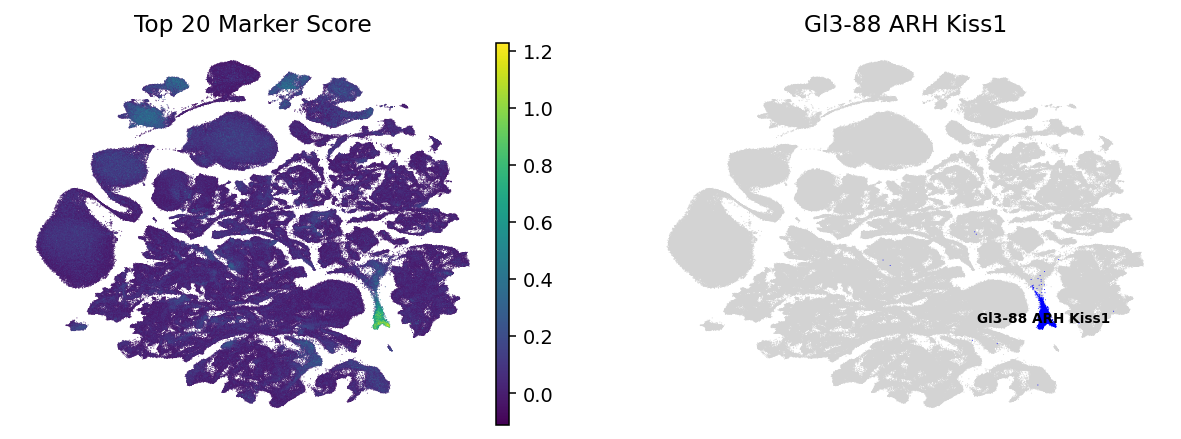

In [31]:
# Visualize marker score and cluster location on UMAP
fig, axes = plt.subplots(1, 2, figsize=(270*MM, 90*MM), dpi=140)

# Marker score -------------------------------------------------------------- #
sc.pl.umap(
    adata,
    color='marker_score',
    ax=axes[0],
    show=False,
    frameon=False,
    title='Top 20 Marker Score',
    s=1
)

# Highlight KNDy cluster ---------------------------------------------------- #
sc.pl.umap(
    adata,
    color='L3_descr',
    groups=['Gl3-88 ARH Kiss1'],
    ax=axes[1],
    show=False,
    frameon=False,
    palette='gist_rainbow',
    legend_loc='on data',
    legend_fontsize=7,
    title='Gl3-88 ARH Kiss1',
    s=1,
    na_in_legend=False
)

plt.show()
plt.close()

## Subtype analysis at L4

The KNDy population splits into multiple subtypes at **L4**.
However, L3 marker genes alone provide limited discriminatory power.

Below, we:
1. Visualize expression of canonical KNDy genes
2. Examine subtype separation using dotplots

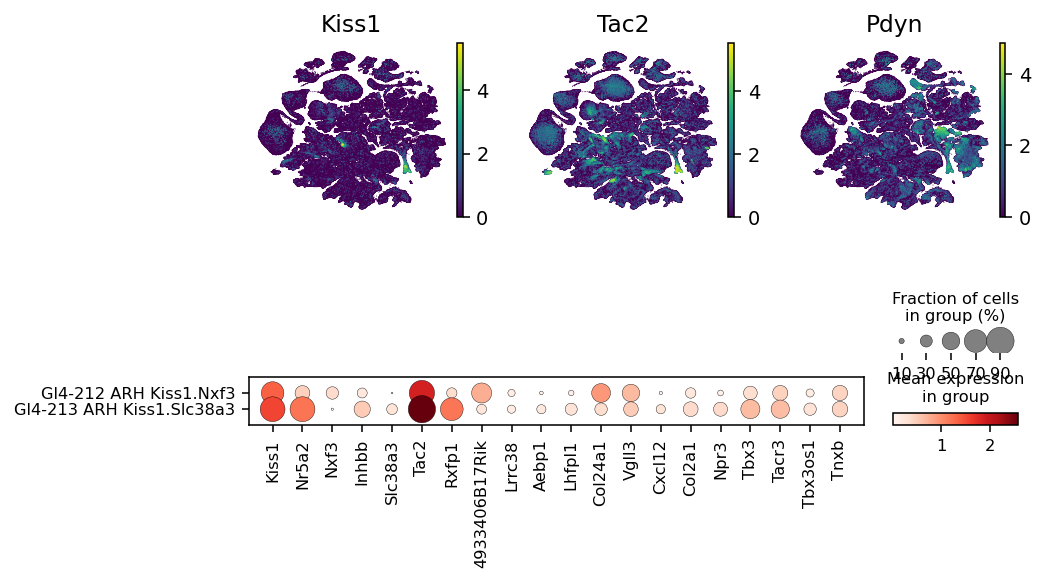

In [32]:
mask = adata.obs['L3_descr'] == 'Gl3-88 ARH Kiss1'

mosaic = [
    ['Kiss1', 'Tac2', 'Pdyn'],
    ['dotplot', 'dotplot', 'dotplot']
]

fig, axes = plt.subplot_mosaic(
    mosaic,
    figsize=(180*MM, 90*MM),
    dpi=140
)

# Gene expression UMAPs ----------------------------------------------------- #
for gene in ['Kiss1', 'Tac2', 'Pdyn']:
    sc.pl.umap(
        adata,
        color=gene,
        ax=axes[gene],
        show=False,
        frameon=False,
        title=gene,
        s=1
    )

# Marker dotplot ------------------------------------------------------------ #
sc.pl.dotplot(
    adata[mask],
    var_names=top_20_markers,
    groupby='L4_descr',
    ax=axes['dotplot']
)

plt.show()
plt.close()

## Improved subtype resolution using sister markers

To better discriminate closely related subtypes, we use **sister marker genes**
(markers defined by comparison against sibling clusters rather than all clusters).


In [36]:
# Extract only markers genes with comparison OneVsSisters
df_markers_vs_sister = df_markers[
    df_markers['comparison'] == 'OneVsSisters'
]

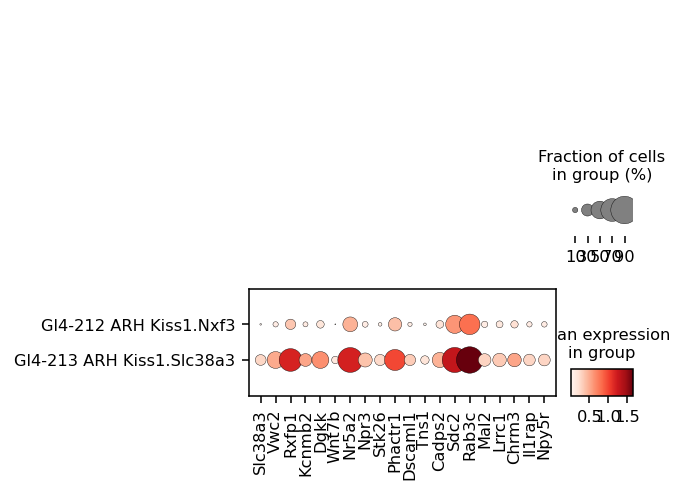

In [41]:
# Select markers for a specific L4 subtype
subtype_markers = df_markers_vs_sister[
    df_markers_vs_sister['celltype_descr'] == 'Gl4-213 ARH Kiss1.Slc38a3'
]

top_subtype_markers = (
    subtype_markers
    .sort_values('rank', ascending=True)
    ['gene_name']
    .head(20)
    .tolist()
)

fig, ax = plt.subplots(1, 1, figsize=(90*MM, 90*MM), dpi=140)

sc.pl.dotplot(
    adata[mask],
    var_names=top_subtype_markers,
    groupby='L4_descr',
    ax=ax
)

plt.show()
plt.close()